# 8 - Forecasting

In this phase, I'll use many of the data gathered in phase 6 (Seasonality analysis) to decide the next steps.

Phase 6 told what kinds of temporal structure seems to exist and that there was some autocorrelation. Now, Phase 8 asks whether that structure and correlation are actually useful for predictions.

So Phase 6 found two different kinds of time dependence in the SP500 Index:

- Raw daily returns: only a small negative autocorrelation (yesterday's return has a weak link to today's)
- Squared returns (an approximate measure of volatility): strong, slowly fading autocorrelation. Big movement days tend to be followed by more big movement days (volatility clustering)

A pattern that exists in past data is not automatically useful for prediction. In this Phase 8 an important question is asked:

`Does the historical structure improve forecasts on data that the model has never seen, compared with a naive guess (the baseline)?`

For this I will focus on:

- Daily return: find tomorrow's SP500 return.
- Volatility: How much the SP500 will move over the next 21 trading days.

Important rules:
- Only the SP500 index series will be used. This project's cleanest time series. No stocks nor sectors.
- The time order is never broken (models only ever see the past data).
- The goal of the model is to beat a simple baseline, the naive forecast. 
- This is a forecasting accuracy exercise, not a trading strategy (will try to confirm past returns and not predict future returns).


Import libraries:

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path
from statsmodels.tsa.stattools import adfuller
#Augmented Dickey-Fuller (ADF) to test whether a time series is stationary.



Load data:

In [ ]:
#Only using the SP500 to forecast.
features_path=Path(r"D:\Documentos\DA Projects\sp500-market-analysis\csv_features")
stats_path=Path(r"D:\Documentos\DA Projects\sp500-market-analysis\csv_stats")

#For that i just need the date, simple_return and the actual daily sp500 value
index_features=pd.read_csv(features_path / "index_features.csv", usecols=["date","sp500","simple_return"], parse_dates=["date"])

#Now remove the null records for simple returns:
index_data=index_features.dropna(subset=["simple_return"]).set_index("date").sort_index()

#These will be used throughout the project, so i want to have them already calculated:
dates=index_data.index
returns_series=index_data["simple_return"].to_numpy()

n=len(index_data)
#2516

train_end_date="2021-12-31"
#This date provides roughly 70% of all dates as training data, so 30% of test data.
#I want full years only. 
#dates.quantile(0.70) -> 2021-12-20
#Knowing this i decided to get the full year which represents:
#(dates<=pd.to_datetime("2021-12-31")).mean() -> 70,31%

#Number of test days:
num_test_days=int((dates > pd.Timestamp(train_end_date)).sum())
#747 days


#### 8.1 Why model returns and not prices? (stationarity assessment)

As already discussed, prices trend up over time, so their average level can change.  

Daily returns, on the other hand, often fluctuate around a relatively stable mean near zero. This distinction matters because time-series forecasting models work best when the statistical properties of the data remain stable over time (mean, variance and autocorrelation remain stable over time). Different forecasting models make different assumptions about the data, so checking stationarity helps identify which modeling approach is appropriate. 

Now let's formally test the intuition using the ADF test (augmented dickey-fuller).

The ADF test requires:

.A one-dimensional time series (pandas Series or NumPy array).  
.Numerical observations.  
.No missing values (NaN) or infinite values.  
.Observations in chronological order, ideally at a consistent frequency.  

ADF hypothesis:
- H0: The series has a unit root and is non-stationary.
- H1: The series has no unit root, consistent with stationarity under the specified test model.
  
* unit root: shocks have permanent effects on the level of a time series, rather than fading away (it drifts and does not settle around a stable level).




Plotting the SP500 price and simple_return to visually see their trend:

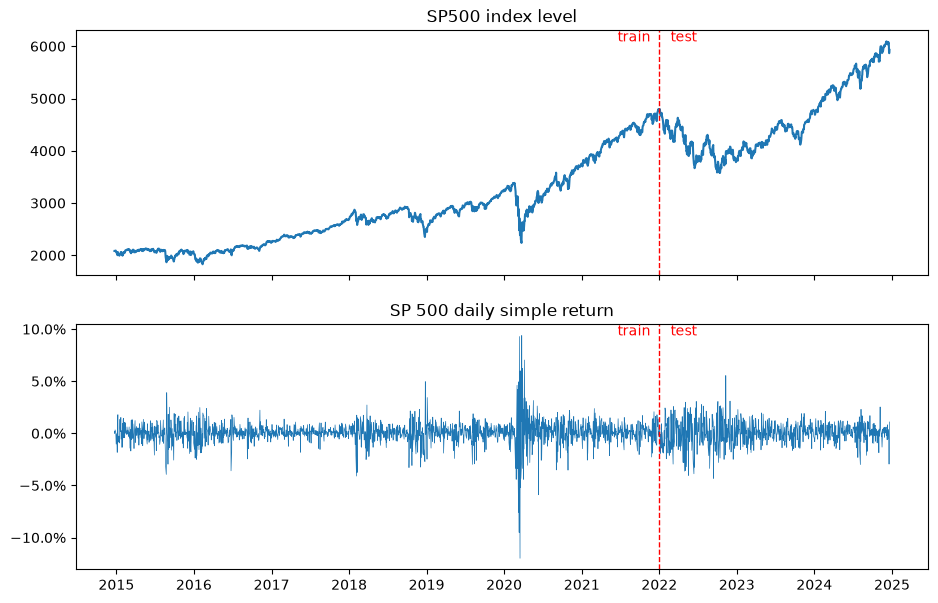

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
#sharex= both plots share the same x axis.

axes[0].plot(index_data.index,index_data["sp500"])
axes[0].set_title("SP500 index level")

axes[1].plot(index_data.index,index_data["simple_return"], linewidth=0.5)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_title("SP 500 daily simple return")

for ax in axes:
    ax.axvline(pd.Timestamp(train_end_date), color="red", linestyle="--", linewidth=1)
#to add the vertical line to the 2 plots

axes[0].text(pd.Timestamp(train_end_date), axes[0].get_ylim()[1], "  train     test   ", va="top", ha="center", color="red")

axes[1].text(pd.Timestamp(train_end_date), axes[1].get_ylim()[1], "  train     test   ", va="top", ha="center", color="red")

plt.show()


Running ADF:

In [ ]:
def run_adf(series, name):

    stat, pvalue, used_lag, n_obs, crit, _ = adfuller(series, autolag="AIC")
    print(f"{name}") #or just print(name)
    print(f"ADF statistic = {stat:.4f}, p-value = {pvalue:.6f}")
    print("Critical Values:", {k: round(v, 4) for k, v in crit.items()})

train_date_mask = (index_data.index <= pd.Timestamp(train_end_date))

run_adf(index_data.loc[train_date_mask, "sp500"], "SP500 Index (training period)")
#.loc runs the test just for the rows that match the train_mask condition and the column sp500
print()
run_adf(index_data.loc[train_date_mask, "simple_return"], "Daily return (training period)")

# Results:
# SP500 Index (training period)
# ADF statistic = 0.8854, p-value = 0.992897
# Critical Values: {'1%': -3.4341, '5%': -2.8632, '10%': -2.5676}

# Daily return (training period)
# ADF statistic = -13.3218, p-value = 0.000000
# Critical Values: {'1%': -3.4341, '5%': -2.8632, '10%': -2.5676}

#SP 500 Index: p-value = 1. Cannot reject H0, so we cannot say that there's no unit root, 
# therefore there's no evidence confirming that the index is stationary.
#Daily return: p-value < 0.01, so there's strong evidence that we can reject H0, suggesting 
# that daily returns could be stationary (there's no unit root).



SP500 Index (training period)
ADF statistic = 0.8854, p-value = 0.992897
Critical Values: {'1%': -3.4341, '5%': -2.8632, '10%': -2.5676}

Daily return (training period)
ADF statistic = -13.3218, p-value = 0.000000
Critical Values: {'1%': -3.4341, '5%': -2.8632, '10%': -2.5676}


#### 8.2 Forecasting setup

In this section, I'm applying my time split (training data contains all ordered dates before 2021-12-31) but with a twist. The first test date will include all dates right until 2021-12-31, so all the past dates, but for the second test date, I also need to include the first test date because in day 2, I have the data of day 1 plus all the previous days' data. In other words, I'm not applying a single fit on the training period but instead I will apply a forever expanding window. So, these will be the steps:

1. For the first day, my model will have everything before it and will predict that day.
2. Compare the prediction vs the actual value.
3. Move to the next day. This time window will be one day longer than what was used for the first day, because it includes everything everything before that first day and it also includes that first day. Predict and reveal.
4. Repeat until the end.

At every step, the model only knows the past.

The goal: For every trading day from 2022 to 2024, make a few guesses of that day's return using only earlier data. Then measure which guess was closest on average.

I will use the zero forecast (no gain or loss is expected) as the baseline to compare the improvement, if any, of my models.

The metrics that will be used to evaluate the forecast are:
- MAE (mean absolute error): Measures the average absolute difference between actual and predicted values (ignores direction). An MAE of 0.5% means the forecast is off by 0.5 percentage points on average. MAE of 1.5, means that my predictions were off by an average of 1.5 percentage points.

1/n x SUM(|actual value - predicted value|)

- RMSE (root mean squared error): squares each miss first, so large misses count more. Similar to MAE, but penalizes large errors more heavily. If MAE and RMSE disagree on which model is better, one model usually has few large errors.  

SQR(1/n x SUM(actual value - predicted value)^2)

The improvement % will be determined by comparing each model with a reference baseline:

(baseline error - model error) / baseline error

Positive mean better than the baseline. These differences will not be formally tested for statistical significance (see limitations), so small differences should not be over-read.


**What I need:**

df -> all the sp500 daily returns.

test start -> position where the test period begins.

actual ret -> the actual return during the test period.

MAE and RMSE -> what i will use to measure how inaccurate the predictions were.

**Steps:**

1. Use historical returns (return_series).
2. Apply 4 forecasting models (zero, mean, yesterday's and AR(1)).
3. Compare predicted returns with actual returns.
4. Calculate MAE and RMSE.
5. Conclude which model is better.

yesterday Vs AR(1) - both use the previous day's return, but AR(1) model estimates alpha and phi from historical data, whilst yesterday's model assume both intercept (alpha) and coefficient (phi) as zero and one respectively.

Why lag 1 and not other lag for AR():
Because in ths project, lag 1 is the only lag that i have a clear prior reason to test.
Phase 6 ACF showed that raw S&P 500 returns had only weak autocorrelation overall, but the most noticeable short-run relationship was at lag 1. So AR(1) is the simplest model that directly asks: “Does yesterday’s return help predict today’s return?”
Using AR(2), AR(5), AR(10), etc. would mean assuming that returns from 2, 5, 10 days ago add useful predictive information. I could test that, but the earlier analysis did not give me a strong reason to expect it.


In AR(1):

Rt+1=alpha + phi.Rt + Et+1

alpha and phi will be constantly re-estimated as the days of our testing period progresses.




Get the train and the test period:

In [5]:
train = index_data.loc[index_data.index <= train_end_date] #pandas label based indexer 
#or index_data[index_data.index<train_end_date] - boolean indexing
test = index_data.loc[index_data.index > train_end_date]
#or index_data[index_data.index>=train_end_date]

print("training period:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} days)")
#the date() is to remove the timestamp.
print("test period:", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} days)")

# Results:
# training period: 2014-12-23 to 2021-12-30 (1769 days)
# test period: 2021-12-31 to 2024-12-20 (747 days)


training period: 2014-12-23 to 2021-12-31 (1769 days)
test period: 2022-01-03 to 2024-12-20 (747 days)


#### 8.3 Can daily returns be forecast?

**Q:** can tomorrow's return be predicted from past returns better than a naive guess?

**Baselines:**
- Zero: always predict 0%. Average daily returns are tiny compared with their day-to-day swings.
- Historical mean: always predict the average return of all days so far.
- Yesterday's return: predict that tomorrow will be the same as today's.

**Model used:** For this I will use the autoregressive model of order 1, AR(1). It predicts today's return as a constant plus a fraction of yesterday's return.
AR(1) autoregressive model:
- auto means a variable is related to itself.
- Regressive refers to using a statistical relationship to estimate the variable. 
- Order 1 means you use one lag (the previous day's return).

Rt= c + (phi . Rt-1) + error

.rt - return today
.rt-1 - return yesterday
.c - intercept (baseline component of the return)
.phi - slope (how yesterday's return relates to today's) [phi>0 positive autocorrelation]
.error - unpredictable part of today's return.

The model creates pairs of consecutive observations. And asks if there is a straight line relationship between the return yesterday and the return today.

This is basically the same concept idea as beta in Phase 7 - draw a straight line through the cloud of dots (yesterday's return on the x-axis and today's return on the y-axis) and the slope is phi. A negative phi means that yesterday's movement has the opposite effect on today's return. Phase 6 indicated a weak autocorrelation between returns, so now I want to see if that weak pattern can help this forecast.

In [ ]:
#1-Preparing the main table that will present the actual and predicted values:
df=index_data[["simple_return"]].rename(columns={"simple_return":"actual"})


#2-Getting the various baselines into actual columns in this new df:
df["zero"]=0.0
df["hist_mean"]=df["actual"].expanding().mean().shift(1)
#shift(1) makes sure that on each day, i only use info from previous days - no look ahead.
df["yesterday"]=df["actual"].shift(1)

#3-AR(1): for each test day, fit a line on all earlier days, then predict:
df["ar1"]=np.nan
df["phi"]=np.nan
df["c"] = np.nan


for date in df.index[df.index > train_end_date]:
    #Get the information available before that date to use to predict.
    past=df.loc[df.index < date, "actual"] #.dropna() not needed cause i already removed NaNs
    #only days before the one we are at.
    #gathers the historical returns (testing period)
    
    #Estimate the model:
    phi, c = np.polyfit(past.iloc[:-1], past.iloc[1:],1)

    df.loc[date,"ar1"]=c+phi*past.iloc[-1]
    #predict the next return using the latest known value (previous day where we are at)
    df.loc[date,"phi"]=phi
    #saving the slope
    df.loc[date,"c"]=c
    

#4. Score only the test period:
#only the testing period:
test_ret=df.loc[df.index>train_end_date]
#list of methods to iterate the column in the errors table:
methods=["zero","hist_mean","yesterday","ar1"]
#forecast error for every forecasting method on every test date.
errors=test_ret[methods].sub(test_ret["actual"],axis=0)


ret_results = pd.DataFrame({
    "MAE": errors.abs().mean(),
    "RMSE": np.sqrt((errors ** 2).mean()),
#MAE= 1/n x SUM(|actual value - predicted value|) -> how large the errors are on average 
#RMSE= SQR(1/n x SUM(actual value - predicted value)^2) -> highlights models that occasionally make large mistakes.
})


# improvement over the reference baseline (zero); positive = better than zero
ret_results["MAE_improvement_%"]=(ret_results.loc["zero","MAE"]-ret_results["MAE"]) / ret_results.loc["zero", "MAE"] * 100
#gets our baseline "zero" MAE and subtracts with every method's MAE (goes down the column)
ret_results["RMSE_improvement_%"] = (ret_results.loc["zero", "RMSE"]-ret_results["RMSE"]) / ret_results.loc["zero", "RMSE"] * 100
ret_results

# 	        MAE	        RMSE	    MAE_improvement_%	RMSE_improvement_%
# zero	    0.008127	0.011034	0.000000	        0.000000
# hist_mean	0.008124	0.011032	0.045386	        0.017111
# yesterday	0.011648	0.015458	-43.321840	        -40.090960
# ar1	    0.008358	0.011218	-2.837079	        -1.670432

,MAE,RMSE,MAE_improvement_%,RMSE_improvement_%
zero,0.008127,0.011034,0.000000,0.000000
hist_mean,0.008124,0.011032,0.045386,0.017111
yesterday,0.011648,0.015458,-43.321840,-40.090960
ar1,0.008358,0.011218,-2.837079,-1.670432


In [7]:
best_baseline_mae = ret_results.loc[["zero", "hist_mean", "yesterday"], "MAE"].idxmin()
print("Best baseline MAE:", best_baseline_mae)
print("AR(1) beats the best baseline on MAE:", bool(ret_results.loc["ar1", "MAE"] < ret_results.loc[best_baseline_mae, "MAE"]))


best_baseline_rmse = ret_results.loc[["zero", "hist_mean", "yesterday"], "RMSE"].idxmin()
print("Best baseline RMSE:", best_baseline_rmse)
print("AR(1) beats the best baseline on RMSE:", bool(ret_results.loc["ar1", "RMSE"] < ret_results.loc[best_baseline_rmse, "RMSE"]))

print("\nphi (the AR(1) slope) as it was re-estimated across the test period:")
print(test_ret["phi"].describe())
print()
print(test_ret["c"].describe())

Best baseline MAE: hist_mean
AR(1) beats the best baseline on MAE: False
Best baseline RMSE: hist_mean
AR(1) beats the best baseline on RMSE: False

phi (the AR(1) slope) as it was re-estimated across the test period:
count    747.000000
mean      -0.156114
std        0.015927
min       -0.199832
25%       -0.163175
50%       -0.151471
75%       -0.144468
max       -0.137470
Name: phi, dtype: float64

count    747.000000
mean       0.000498
std        0.000046
min        0.000400
25%        0.000459
50%        0.000494
75%        0.000534
max        0.000643
Name: c, dtype: float64


The expanding historical mean produced the lowest MAE and RMSE, but its advantage over the zero-return baseline was practically negligible.

Phi - throughout the test period the fitted model kept finding a modest negative relationship, which means that, a positive return yesterday is associated, on average, with some tendency toward a lower return today, and vice versa.

“tomorrow = yesterday” performed terribly - phi approx -0.156 so data shows some short-run reversal rather than persistence. 

c = 0.0005 (0.05% daily), so if yesterday's return were exactly zero, the AR(1) prediction would be around +0.05%.

Phase 6 connection: Phase 6, ACF found a small negative lag-1 autocorrelation, roughly -0.14. This means, historically, if yesterday's return was relatively high, today's return has a slight tendency to be lower, and vice versa. In Phase 8, phi=-0.156, basically the same negative relationship again. The new question in Phase 8 was "Is that relationship strong and stable enough to make better predictions of unseen returns?", and the answer was no.

Main conclusions:  
.The expanding historical mean forecast achieved the lowest MAE and RMSE, although its improvement over the zero-return baseline was negligible (approximately 0.05% for MAE and 0.02% for RMSE).   
.The AR(1) model consistently estimated a modest negative lag-1 coefficient (mean phi approx-0.156), confirming the short-run negative autocorrelation observed in Phase 6. However, this relationship did not translate into improved out-of-sample forecasting accuracy: AR(1) performed approximately 2.9% worse than the historical-mean baseline on MAE and 1.7% worse on RMSE.   
.The naive yesterday-return forecast performed substantially worse, consistent with the observed negative rather than positive lag-1 relationship.  
.Overall, daily index returns showed little practically useful one-day-ahead predictability, and simple near-zero forecasts were difficult to beat.

#### 8.4 Can volatility be used to forecast?

Phase 6 gave a much stronger reason to expect predictability here: squared returns stayed autocorrelated over many lags (volatility clustering). Volatility comes from returns and i already showed that those are stationary.

Metrics:
- Trailing volatility on day t: the std deviation of the last 21 daily returns (one month that includes day t). Plain daily units.
- Realized volatility (what I'm forecasting): the std deviation of the next 21 daily returns, after day t. 

Baselines:
- trailing volatility (i.e. "yesterday's" becomes 20 days prior plus the actual day's return): "the next month will be as volatile as the last month". Because volatility clusters, this may already be hard to beat.
- Long run avg volatility (i.e. historical mean): the avg trailing volatility seen so far. It ignores recent conditions, so it shows how much recent history actually matters.

Model:
- lagged volatility regression. Fit a straight line:

next 21 day volatility = c + phi x trailing volatility (std previous 21 days on date t)



Important: No using future data to train the model. On forecast day t, the model can only be fitted on pairs that are already complete.

s + 21 <= t

s- the day on which the training example begins.
21 - the number of days in the forecast horizon.
t - the day on which you are making a forecast.

This formula means that the training example's target must finish on or before the forecast day. If we rearrange:

s ≤ t− 21

So, on Day 30, the model can only use training examples beginning on Day 9 or earlier.

We use the most recent 21 trading days to estimate current volatility and forecast realized volatility over the next 21 trading days. We don't forecast a directly observed single-day standard deviation because one daily return is not enough to calculate volatility. Single-day squared or absolute returns could be used as proxies, but the 21-day target is smoother, directly measurable from daily data, and better aligned with the volatility persistence found in Phase 6.


Why not:

.I did not use **zero** as a primary volatility baseline because 21-day realized volatility is non-negative and normally materially above zero, making zero an unrealistically weak benchmark. Technically, 21-day volatility can equal zero if all 21 returns are identical, so this is very unlikely.  

.Why **not single-day volatility**: a single day has only one return, so there’s nothing to take a spread of. That day’s volatility can’t be observed.

.Nothing stops you from saying **“given the last 21 days, I expect tomorrow to be about this volatile”**. The real problem is scoring it. When tomorrow comes, you can’t see its volatility. You only see tomorrow’s return, and you’d compare your forecast against its size (|return|). One day’s absolute return or squared return is a very noisy stand-in for volatility.

.Use **today's 21-day volatility to predict tomorrow's trailing 21-day volatility.**
Today's 21-day vol: returns t-20 ... t
Tomorrow's 21-day vol: returns t-19 ... t+1
But notice that those two measurements share 20 out of 21 returns. So tomorrow's rolling volatility is almost today's rolling volatility by construction. A model would look impressively accurate partly because you're essentially predicting a number made from 95% of the same data.



In [ ]:
## 1. One table: returns, trailing volatility, and the volatility we want to forecast
volatility_df=index_data[["simple_return"]].copy()#.rename(columns={"simple_return": "ret"})

volatility_df["trailing_std"]=volatility_df["simple_return"].rolling(21).std() 

volatility_df["actual_std"] = volatility_df["trailing_std"].shift(-21)

volatility_df["known_on"]=volatility_df.index.to_series().shift(-21)


## 2. Baselines:
volatility_df["21_trailing"]=volatility_df["trailing_std"]
volatility_df["long_run"]=volatility_df["trailing_std"].expanding().mean()



## 3. Regression (Can past volatility help predict future volatility?):
volatility_df["regression"]=np.nan #each day's predicted volatility
volatility_df["slope"]=np.nan #the slope for each day's regression
volatility_df["constant"]=np.nan #constant or intercept

for date in volatility_df.index[(volatility_df.index > train_end_date)&(volatility_df["actual_std"].notna())]:

    #training period:
    known=volatility_df.loc[volatility_df["known_on"]<=date].dropna(subset=["21_trailing","actual_std"])

    
    phi, c=np.polyfit(known["trailing_std"], known["actual_std"],1)

    volatility_df.loc[date,"regression"]=c+phi*volatility_df.loc[date,"trailing_std"]
    volatility_df.loc[date,"slope"]=phi
    volatility_df.loc[date,"constant"]=c


## 4. Score only the test days:

test_vol=volatility_df.loc[(volatility_df.index > train_end_date)& volatility_df["actual_std"].notna()]
#filtering just my testing dates

vol_methods=["21_trailing","long_run","regression"]

vol_errors=test_vol[vol_methods].sub(test_vol["actual_std"],axis=0)

vol_results=pd.DataFrame({
    "MAE": vol_errors.abs().mean(),
    #absoluting the differences and then using mean (sums and divides by obs which are our pairs)
    "RMSE": np.sqrt((vol_errors**2).mean())
})
#MAE= 1/n x SUM(|actual value - predicted value|) -> how large the errors are on average 
#RMSE= SQR(1/n x SUM(actual value - predicted value)^2) -> highlights models that occasionally make large mistakes.


# improvement over the reference baseline (trailing volatility carried forward)
vol_results["MAE_improvement_%"]=(vol_results.loc["21_trailing","MAE"]-vol_results["MAE"]) / vol_results.loc["21_trailing", "MAE"] * 100
vol_results["RMSE_improvement_%"] = (vol_results.loc["21_trailing", "RMSE"] - vol_results["RMSE"]) / vol_results.loc["21_trailing", "RMSE"] * 100
#both trailing and historical are my baselines, but i just picked trailing as reference.

# 	            MAE	        RMSE	    MAE_improvement_%	RMSE_improvement_%
# 21_trailing	0.002418	0.003198	0.000000	        0.000000
# long_run	    0.003487	0.004372	-44.201911	        -36.680334
# regression	0.002434	0.003172	-0.651389	        0.830644


- Long-run average is clearly worse than trailing volatility. It is about 44% worse on MAE and 37% worse on RMSE. Recent conditions matter a lot, which is what you’d expect from volatility clustering.
- Trailing volatility is the best baseline.
- The regression is a tie. It is 0.83% better on RMSE and 0.65% worse on MAE. The two metrics disagree on direction and both gaps are tiny, so it does not meaningfully beat carrying trailing volatility forward.

In [9]:
print("slope stats:",test_vol["slope"].describe())
print()
print("constant stats:",test_vol["constant"].describe())

# slope stats: count    726.000000  (747 - last 21 days)
# mean       0.510187
# std        0.011614
# min        0.481770
# 25%        0.504817
# 50%        0.515383
# 75%        0.517194
# max        0.521977
# Name: slope, dtype: float64

# constant stats: count    726.000000
# mean       0.004653
# std        0.000081
# min        0.004466
# 25%        0.004573
# 50%        0.004672
# 75%        0.004726
# max        0.004761
# Name: constant, dtype: float64


slope stats: count    726.000000
mean       0.510187
std        0.011614
min        0.481770
25%        0.504817
50%        0.515383
75%        0.517194
max        0.521977
Name: slope, dtype: float64

constant stats: count    726.000000
mean       0.004653
std        0.000081
min        0.004466
25%        0.004573
50%        0.004672
75%        0.004726
max        0.004761
Name: constant, dtype: float64


- The slope is consistently around 0.51, suggesting a positive relationship between past volatility and future volatility, with half the strength. In other words, the volatility forecast is roughly half of the last month's volatility.
- Minimum: 0.4818 and maximum: 0.5220 - The slope stays positive across all 726 forecasts.
- Standard deviation: 0.0116 - The slope varies relatively little over time.
  

#### Plotting:

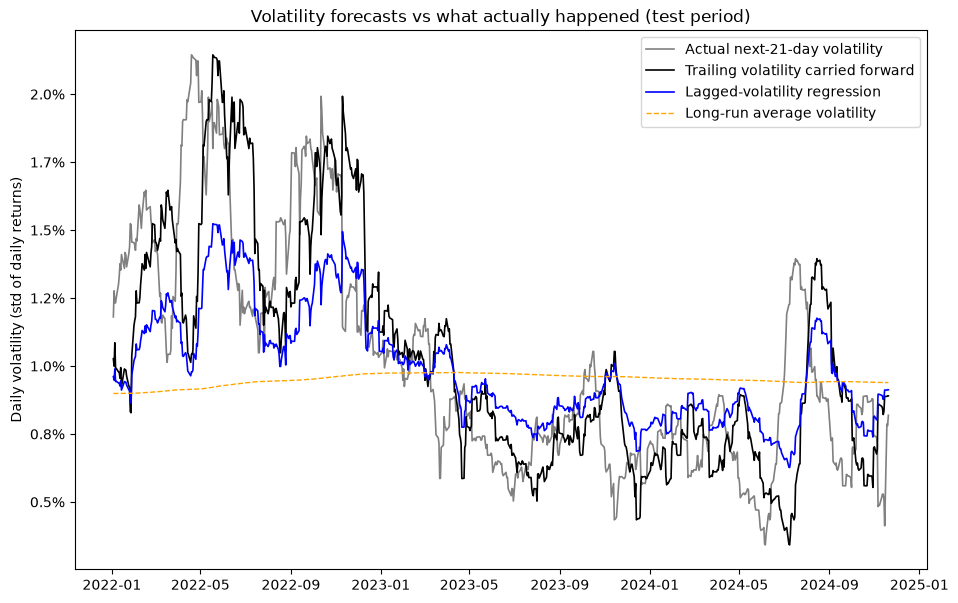

In [10]:
fig, ax= plt.subplots(figsize=(11,7))

ax.plot(test_vol.index, test_vol["actual_std"], color="grey", linewidth=1.2, label="Actual next-21-day volatility")
ax.plot(test_vol.index, test_vol["21_trailing"], color="black", linewidth=1.2, label="Trailing volatility carried forward")
ax.plot(test_vol.index, test_vol["regression"], color="blue", linewidth=1.2, label="Lagged-volatility regression")
ax.plot(test_vol.index, test_vol["long_run"], color="orange", linewidth=1, linestyle="--", label="Long-run average volatility")

ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))

ax.set_ylabel("Daily volatility (std of daily returns)")
ax.set_title("Volatility forecasts vs what actually happened (test period)")
ax.legend()

#### 8.5 Out of sample verdict:

In [11]:
summary=pd.concat({"Daily return": ret_results, "21-day volatility": vol_results}).reset_index(names=["metric","model"])
summary

,metric,model,MAE,RMSE,MAE_improvement_%,RMSE_improvement_%
0,Daily return,zero,0.008127,0.011034,0.000000,0.000000
1,Daily return,hist_mean,0.008124,0.011032,0.045386,0.017111
2,Daily return,yesterday,0.011648,0.015458,-43.321840,-40.090960
3,Daily return,ar1,0.008358,0.011218,-2.837079,-1.670432
4,21-day volatility,21_trailing,0.002418,0.003198,0.000000,0.000000
5,21-day volatility,long_run,0.003487,0.004372,-44.201911,-36.680334
6,21-day volatility,regression,0.002434,0.003172,-0.651389,0.830644


In [12]:
# Does the model beat the BEST baseline of its task?
print("Returns:")
best_baseline_mae = ret_results.loc[["zero", "hist_mean", "yesterday"], "MAE"].idxmin()
print("Best baseline MAE:", best_baseline_mae)
print("AR(1) beats the best baseline on MAE:", bool(ret_results.loc["ar1", "MAE"] < ret_results.loc[best_baseline_mae, "MAE"]))
print()
best_baseline_rmse = ret_results.loc[["zero", "hist_mean", "yesterday"], "RMSE"].idxmin()
print("Best baseline RMSE:", best_baseline_rmse)
print("AR(1) beats the best baseline on RMSE:", bool(ret_results.loc["ar1", "RMSE"] < ret_results.loc[best_baseline_rmse, "RMSE"]))
print()
print()
print("Volatility:")
best_baseline_vol_mae = vol_results.loc[["21_trailing", "long_run"], "MAE"].idxmin()
print("Best baseline MAE:", best_baseline_vol_mae)
print("Regression beats the best baseline on MAE:", bool(vol_results.loc["regression", "MAE"] < vol_results.loc[best_baseline_vol_mae, "MAE"]))
print()
best_baseline_vol_rmse = vol_results.loc[["21_trailing", "long_run"], "RMSE"].idxmin()
print("Best baseline RMSE:", best_baseline_vol_rmse)
print("Regression beats the best baseline on RMSE:", bool(vol_results.loc["regression", "RMSE"] < vol_results.loc[best_baseline_vol_rmse, "RMSE"]))

# 21_trailing	0.002418	0.003198	0.000000	        0.000000
# long_run	    0.003487	0.004372	-44.201911	        -36.680334
# regression	0.002434	0.003172	-0.651389	        0.830644

Returns:
Best baseline MAE: hist_mean
AR(1) beats the best baseline on MAE: False

Best baseline RMSE: hist_mean
AR(1) beats the best baseline on RMSE: False


Volatility:
Best baseline MAE: 21_trailing
Regression beats the best baseline on MAE: False

Best baseline RMSE: 21_trailing
Regression beats the best baseline on RMSE: True


- Returns: nothing beat the best baseline (hist_mean).
- Volatility: the regression beat trailing volatility on RMSE by 0.8% but lost on MAE, so basically, a tie. Last month's volatility is a strong baseline that a simple linear model did not improve on.

#### Saving results:

In [13]:
destination = Path(r"D:\Documentos\DA Projects\sp500-market-analysis\csv_stats")
summary.to_csv(destination / "forecast_results.csv", index=False)

#### Conclusion

Daily S&P 500 returns showed that past returns contained very little useful forecasting information for tomorrow's return. The expanding historical mean achieved the lowest forecast error, but only marginally outperformed a zero-return forecast, while AR(1) failed to beat the naive baselines despite consistently estimating negative lag-1 dependence.

Volatility was much more persistent. Recent 21-day volatility clearly outperformed the expanding long-run average, although a simple regression on trailing volatility did not meaningfully improve on carrying recent volatility forward.

